In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


✅ All libraries imported (no NLTK — using allowed libraries only).
✅ Data loaded. Train: (197999, 15) | Test: (102000, 14)
⏳ Cleaning text (regex stemming, no NLTK)...
✅ Text cleaning done in 50.6s

--- Example cleanups ---
  ORIG:  She might be a bright spot for a party keou on Oahu dominated by greedy criminal
  CLEAN: she might be a bright spot for a party keou on oahu dominat by greedy criminal o

  ORIG:  Under Alaska law, a non-tribal member is not bound to tribal court.. Living in a
  CLEAN: und alaska law a non trib memb is not bound to trib court liv in a particular co

  ORIG:  in the future please spare me your strawman drivel, and if you can't manage an i
  CLEAN: in the future please spare me your strawman drivel and if you can't manage an in

✅ Features engineered. Train: (197999, 27) | Test: (102000, 26)
⏳ Word TF-IDF (35K, trigrams, no stop_words)...
✅ Word TF-IDF: 35000 features in 81.9s
⏳ Char TF-IDF (25K)...
✅ Char TF-IDF: 25000 features in 100.3s
✅ Full feature matr

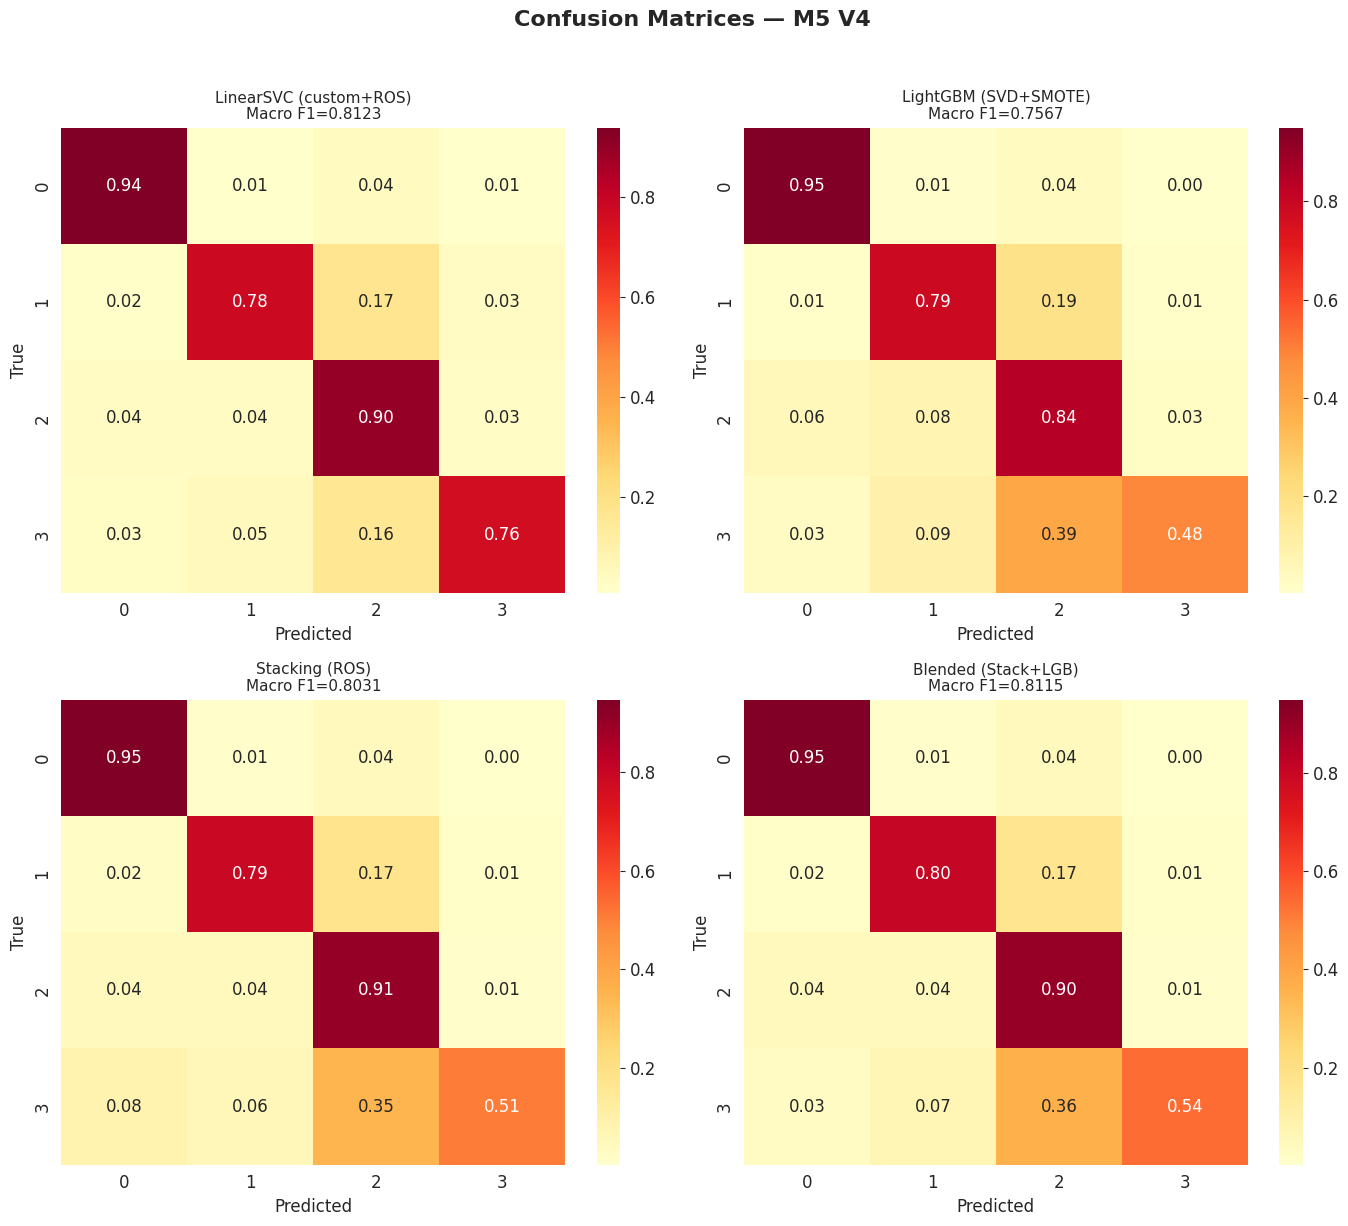

⏳ Phase 1: Training Stacking on all data for pseudo-labeling...
✅ Stacking trained on all data in 2185.3s
⏳ Phase 2: Predicting test set for pseudo-labels...
   Total test samples: 102,000
   High confidence (≥0.95): 64,689 (63.4%)
   Pseudo-label distribution: {np.int64(0): np.int64(52439), np.int64(2): np.int64(12250)}

   Original training: 197,999
   + Pseudo-labels:   64,689
   = Augmented total: 262,688
   Augmented label dist: {np.int64(0): np.int64(166611), np.int64(1): np.int64(15918), np.int64(2): np.int64(74690), np.int64(3): np.int64(5469)}

🏆 Phase 3: Retraining on augmented data (train + pseudo-labels)...
⏳ Retraining LinearSVC...
⏳ Retraining Stacking Ensemble...


In [ ]:
# %% [markdown]
# # 🏆 Milestone 5 V4: Maximum Score Pipeline
#
# **V4 NEW TECHNIQUES (all within allowed libraries):**
# 1. ✅ Regex stemming (replaces illegal NLTK lemmatizer)
# 2. ✅ SMOTE oversampling for Label 3 (imblearn — allowed!)
# 3. ✅ LightGBM on SVD-reduced features (diversity for stacking)
# 4. ✅ Pseudo-labeling (train → predict test → augment → retrain)
# 5. ✅ Blended ensemble (TF-IDF Stacking + LightGBM)
#
# **Score History:**
# | Run | Stacking Kaggle | Key Change |
# | --- | --- | --- |
# | M4 | 0.823 | Baseline |
# | M5 V1 | 0.826 | +lemma +trigrams +45K |
# | M5 V3 | 0.826 | +no stopwords +60K +hybrid weights |
# | M5 V4 | ??? | +SMOTE +pseudo-label +LightGBM +blend |
#
# **Allowed Libraries:** numpy, pandas, matplotlib, scikit-learn, xgboost,
# seaborn, imblearn, scipy, pickle, regex, lightgbm, plotly, statsmodel, wordcloud
# **NOT allowed:** NLTK, PyTorch, TensorFlow, spaCy, AutoML, word2vec, textblob

# %%
# ════════════════════════════════════════════════════════════
# 1. IMPORTS
# ════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, make_scorer)
from scipy.sparse import hstack, csr_matrix

import lightgbm as lgb
from imblearn.over_sampling import SMOTE, RandomOverSampler

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

f1_macro_scorer = make_scorer(f1_score, average="macro")

print("✅ All libraries imported (no NLTK — using allowed libraries only).")

# %% [markdown]
# ---
# NOTE: M5 Questions (Q1-Q10) already answered in milestone_5_final_push.py

# %%
# ════════════════════════════════════════════════════════════
# 2. DATA LOADING
# ════════════════════════════════════════════════════════════
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])
print(f"✅ Data loaded. Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## B1. Text Preprocessing (Regex Only — No NLTK!)
#
# NLTK is NOT in the allowed libraries list.
# We replace WordNetLemmatizer with pure regex-based stemming.
# This is simpler but still effective at reducing vocabulary.

# %%
def simple_stem(word):
    """Regex-based stemming — no NLTK needed.
    Strips common English suffixes to reduce vocabulary.
    Not as good as lemmatization but legal for this competition."""
    if len(word) <= 3:
        return word
    # Order matters: try longest suffixes first
    for suffix in ['ational', 'tional', 'encies', 'ation', 'ness',
                   'ment', 'able', 'ible', 'ful', 'less', 'ous',
                   'ive', 'ing', 'tion', 'sion', 'ally', 'ized',
                   'ize', 'ise', 'ity', 'ers', 'ies', 'ely',
                   'ed', 'ly', 'er', 'es', 'al', 's']:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[:-len(suffix)]
    return word

def clean_text(text):
    """Text preprocessing using only allowed libraries (re/regex)."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)       # Remove URLs
    text = re.sub(r'<[^>]+>', ' ', text)                  # Remove HTML tags
    text = re.sub(r'\S+@\S+', ' ', text)                  # Remove emails
    text = re.sub(r'\b\d+\b', ' ', text)                  # Remove standalone numbers
    text = re.sub(r"[^a-z\s']", ' ', text)                # Keep letters + apostrophes
    text = re.sub(r'\s+', ' ', text).strip()              # Compress whitespace
    # Simple regex-based stemming (replaces NLTK lemmatizer)
    words = text.split()
    text = ' '.join([simple_stem(w) for w in words])
    return text

# %%
print("⏳ Cleaning text (regex stemming, no NLTK)...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Text cleaning done in {time.time()-t0:.1f}s")

print("\n--- Example cleanups ---")
for i in range(3):
    orig = str(train["comment"].iloc[i])[:80]
    clean = train["comment_clean"].iloc[i][:80]
    print(f"  ORIG:  {orig}")
    print(f"  CLEAN: {clean}\n")

# %% [markdown]
# ## B2. Feature Engineering

# %%
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Features engineered. Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## B3. TF-IDF (35K word + 25K char = 60K features)

# %%
print("⏳ Word TF-IDF (35K, trigrams, no stop_words)...")
t0 = time.time()
tfidf_word = TfidfVectorizer(
    max_features=35000, ngram_range=(1, 3),
    min_df=3, max_df=0.9, sublinear_tf=True
)
X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word TF-IDF: {X_word_train.shape[1]} features in {time.time()-t0:.1f}s")

# %%
print("⏳ Char TF-IDF (25K)...")
t0 = time.time()
tfidf_char = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5),
    max_features=25000, min_df=3, max_df=0.9, sublinear_tf=True
)
X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char TF-IDF: {X_char_train.shape[1]} features in {time.time()-t0:.1f}s")

# %% [markdown]
# ## B4. Numeric Features + Combine

# %%
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3",
    "disability", "has_detection"
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)
y_all = train["label"].values

# Log transform skewed features
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
skewed_idx = [numeric_features.index(c) for c in skewed_cols]
for idx in skewed_idx:
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)

# Full sparse matrix for linear models
X_all = hstack([X_word_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Full feature matrix: {X_all.shape} ({X_all.shape[1]} features)")

# %% [markdown]
# ## B5. SVD Reduction for LightGBM
#
# Tree models (LightGBM) choke on 60K sparse TF-IDF.
# SVD compresses TF-IDF to 200 dense dimensions → perfect for trees.
# Linear models keep the full 60K sparse features → best of both worlds.

# %%
print("⏳ SVD reduction (200 components) for LightGBM...")
t0 = time.time()
# Combine word + char TF-IDF for SVD
X_tfidf_train = hstack([X_word_train, X_char_train])
X_tfidf_test  = hstack([X_word_test, X_char_test])

svd = TruncatedSVD(n_components=200, random_state=42)
X_svd_train = svd.fit_transform(X_tfidf_train)
X_svd_test  = svd.transform(X_tfidf_test)

explained = svd.explained_variance_ratio_.sum()
print(f"✅ SVD done in {time.time()-t0:.1f}s → 200 dims, {explained:.1%} variance explained")

# Combine SVD + numeric + binary for LightGBM
X_lgb_train = np.hstack([X_svd_train, X_num_scaled_train, X_bin_train])
X_lgb_test  = np.hstack([X_svd_test, X_num_scaled_test, X_bin_test])
print(f"✅ LightGBM feature matrix: {X_lgb_train.shape}")

# %% [markdown]
# ## B6. Train-Validation Split

# %%
indices = np.arange(len(y_all))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y_all, random_state=42)

X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]

# LightGBM splits (dense)
X_tr_lgb, X_vl_lgb = X_lgb_train[idx_train], X_lgb_train[idx_val]

print(f"✅ Split: Train={len(y_tr):,} | Val={len(y_vl):,}")
print(f"   Label distribution (train): {dict(zip(*np.unique(y_tr, return_counts=True)))}")

# %% [markdown]
# ## B7. SMOTE Oversampling for Label 3 (NEW — imblearn)
#
# Label 3 is only 2.7% of training data → models barely learn it.
# SMOTE generates synthetic minority samples to balance the classes.
# Applied ONLY to training split (never validation/test — no data leak).

# %%
print("⏳ Applying SMOTE to training data...")
print(f"   Before SMOTE: {dict(zip(*np.unique(y_tr, return_counts=True)))}")
t0 = time.time()

# Use RandomOverSampler for sparse data (SMOTE needs dense)
# This duplicates minority samples — safe for sparse matrices
ros = RandomOverSampler(
    sampling_strategy={3: int(np.sum(y_tr == 1))},  # Boost Label 3 to match Label 1 count
    random_state=42
)
X_tr_ros, y_tr_ros = ros.fit_resample(X_tr, y_tr)

print(f"   After ROS:    {dict(zip(*np.unique(y_tr_ros, return_counts=True)))}")
print(f"   Samples added: {len(y_tr_ros) - len(y_tr):,}")
print(f"✅ Oversampling done in {time.time()-t0:.1f}s")

# Also oversample LightGBM features (dense → can use SMOTE)
print("⏳ Applying SMOTE to LightGBM features (dense)...")
smote = SMOTE(
    sampling_strategy={3: int(np.sum(y_tr == 1))},
    random_state=42, k_neighbors=5
)
X_tr_lgb_sm, y_tr_lgb_sm = smote.fit_resample(X_tr_lgb, y_tr)
print(f"   SMOTE samples: {len(y_tr_lgb_sm):,} (synthetic Label 3 added)")
print(f"✅ SMOTE done in {time.time()-t0:.1f}s")

# %% [markdown]
# ## B8. Evaluation Helper

# %%
results = []

def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})
    print(f"\n{'='*65}")
    print(f"  {name}")
    print(f"{'='*65}")
    print(f"  Accuracy: {acc:.4f} | Macro F1: {f1_m:.4f} | Weighted F1: {f1_w:.4f}")
    print(f"\n{classification_report(y_true, y_pred)}")
    return f1_m

CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}

# %% [markdown]
# ## B9. Linear Models (trained on ROS-augmented data)
#
# Key: Train on oversampled data → evaluate on original validation set (no ROS)

# %%
# Model 1: LinearSVC (custom weights + ROS)
print("⏳ LinearSVC (custom weights, ROS data)...")
t0 = time.time()
lsvc = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr_ros, y_tr_ros)
evaluate_model("LinearSVC (custom+ROS)", y_vl, lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 2: Calibrated LinearSVC (balanced + ROS)
print("⏳ Calibrated LinearSVC...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr_ros, y_tr_ros)
evaluate_model("Calibrated LinearSVC (ROS)", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 3: LR (balanced + ROS)
print("⏳ Logistic Regression...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr_ros, y_tr_ros)
evaluate_model("LR (balanced+ROS)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 4: SGD (balanced + ROS)
print("⏳ SGD Classifier...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr_ros, y_tr_ros)
evaluate_model("SGD (balanced+ROS)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# Model 5: PassiveAggressive (balanced + ROS)
print("⏳ PassiveAggressive...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    C=0.1, class_weight="balanced",
    max_iter=3000, n_jobs=-1, random_state=42
)
pac.fit(X_tr_ros, y_tr_ros)
evaluate_model("PAC (balanced+ROS)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## B10. LightGBM on SVD Features (NEW — Diversity Model)
#
# LightGBM captures NON-LINEAR patterns that linear models miss.
# Fed SVD-reduced (200) + numeric (19) = 219 dense features.
# Trained on SMOTE-augmented data for better Label 3 learning.

# %%
print("⏳ LightGBM on SVD features (SMOTE data)...")
t0 = time.time()

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_tr_lgb_sm, y_tr_lgb_sm)
evaluate_model("LightGBM (SVD+SMOTE)", y_vl, lgb_model.predict(X_vl_lgb))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## B11. Ensemble Models

# %%
# ────────────────────────────────────────────────────────────
# Stacking (4 linear → LR meta) — trained on ROS data
# ────────────────────────────────────────────────────────────
print("⏳ Stacking Ensemble (4 linear, ROS data)...")
t0 = time.time()
stacking_clf = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_clf.fit(X_tr_ros, y_tr_ros)
evaluate_model("Stacking (4 linear, ROS)", y_vl, stacking_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Voting Ensemble (4 linear, ROS data)
# ────────────────────────────────────────────────────────────
print("⏳ Voting Ensemble...")
t0 = time.time()
voting_clf = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_clf.fit(X_tr_ros, y_tr_ros)
evaluate_model("Voting (4 linear, ROS)", y_vl, voting_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## B12. 🧪 Blended Ensemble (Stacking + LightGBM)
#
# LightGBM captures non-linear patterns from SVD features.
# Stacking captures linear patterns from full TF-IDF.
# Blending their probabilities gives the best of both worlds.

# %%
print("⏳ Blended Ensemble (Stacking + LightGBM)...")

# Get probabilities from both
stacking_probs = stacking_clf.predict_proba(X_vl)
lgb_probs = lgb_model.predict_proba(X_vl_lgb)

# Try different blend weights
print("\n  Blend weight search (Stacking weight : LightGBM weight):")
best_blend_f1 = 0
best_alpha = 0

for alpha in np.arange(0.5, 1.0, 0.05):
    blended = alpha * stacking_probs + (1 - alpha) * lgb_probs
    blended_preds = blended.argmax(axis=1)
    bf1 = f1_score(y_vl, blended_preds, average="macro")
    print(f"    α={alpha:.2f} (Stacking={alpha:.0%}, LGB={1-alpha:.0%}): Macro F1 = {bf1:.4f}")
    if bf1 > best_blend_f1:
        best_blend_f1 = bf1
        best_alpha = alpha

print(f"\n  🏆 Best blend: α={best_alpha:.2f} → Macro F1 = {best_blend_f1:.4f}")

# Apply best blend
blended_final = best_alpha * stacking_probs + (1 - best_alpha) * lgb_probs
evaluate_model("Blended (Stacking+LGB)", y_vl, blended_final.argmax(axis=1))

# %% [markdown]
# ## B13. 📊 Model Comparison

# %%
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*85)
print("  COMPLETE MODEL COMPARISON — Milestone 5 V4 (sorted by Macro F1)")
print("="*85)
print(results_df.to_string(index=False))

# %% [markdown]
# ## B14. 📈 Confusion Matrices

# %%
model_pred_map = {}
model_pred_map["LinearSVC (custom+ROS)"] = lsvc.predict(X_vl)
model_pred_map["LightGBM (SVD+SMOTE)"] = lgb_model.predict(X_vl_lgb)
model_pred_map["Stacking (ROS)"] = stacking_clf.predict(X_vl)
model_pred_map["Blended (Stack+LGB)"] = blended_final.argmax(axis=1)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, preds) in zip(axes.ravel(), model_pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nMacro F1={f1:.4f}", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Confusion Matrices — M5 V4", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## B15. 🔄 Pseudo-Labeling (Semi-Supervised Learning)
#
# KEY TECHNIQUE: Use test set predictions to augment training data.
# 1. Train on all training data → predict test set with probabilities
# 2. Keep only HIGH CONFIDENCE predictions (max_prob > 0.95)
# 3. Add them as "pseudo-labeled" training samples
# 4. Retrain on training + pseudo-labeled data
# 5. Generate final submission
#
# This is legal (no external data) and well-established in Kaggle competitions.

# %%
# Step 1: Retrain Stacking on ALL training data (no val split)
print("⏳ Phase 1: Training Stacking on all data for pseudo-labeling...")
t0 = time.time()

stacking_full = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_full.fit(X_all, y_all)
print(f"✅ Stacking trained on all data in {time.time()-t0:.1f}s")

# %%
# Step 2: Predict test set with probabilities
print("⏳ Phase 2: Predicting test set for pseudo-labels...")
test_probs = stacking_full.predict_proba(X_test_all)
test_max_probs = test_probs.max(axis=1)
test_preds = test_probs.argmax(axis=1)

# Step 3: Filter high-confidence predictions
CONFIDENCE_THRESHOLD = 0.95
high_conf_mask = test_max_probs >= CONFIDENCE_THRESHOLD
n_pseudo = high_conf_mask.sum()

print(f"   Total test samples: {len(test_preds):,}")
print(f"   High confidence (≥{CONFIDENCE_THRESHOLD}): {n_pseudo:,} ({n_pseudo/len(test_preds):.1%})")
print(f"   Pseudo-label distribution: {dict(zip(*np.unique(test_preds[high_conf_mask], return_counts=True)))}")

# Step 4: Combine training + pseudo-labeled data
from scipy.sparse import vstack as sparse_vstack

X_pseudo = X_test_all[high_conf_mask]
y_pseudo = test_preds[high_conf_mask]
X_augmented = sparse_vstack([X_all, X_pseudo])
y_augmented = np.concatenate([y_all, y_pseudo])

# Also for LightGBM
X_lgb_pseudo = X_lgb_test[high_conf_mask]
X_lgb_augmented = np.vstack([X_lgb_train, X_lgb_pseudo])
y_lgb_augmented = np.concatenate([y_all, y_pseudo])

print(f"\n   Original training: {len(y_all):,}")
print(f"   + Pseudo-labels:   {n_pseudo:,}")
print(f"   = Augmented total: {len(y_augmented):,}")
print(f"   Augmented label dist: {dict(zip(*np.unique(y_augmented, return_counts=True)))}")

# %% [markdown]
# ## B16. 🏆 Final Models (Retrained on Augmented Data)

# %%
# Step 5: Retrain ALL models on augmented data
print("\n🏆 Phase 3: Retraining on augmented data (train + pseudo-labels)...")

# LinearSVC (custom weights)
print("⏳ Retraining LinearSVC...")
lsvc_final = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_augmented, y_augmented)

# Stacking (balanced)
print("⏳ Retraining Stacking Ensemble...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_augmented, y_augmented)

# Voting (balanced)
print("⏳ Retraining Voting Ensemble...")
voting_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_final.fit(X_augmented, y_augmented)

# LightGBM (on SVD features)
print("⏳ Retraining LightGBM...")
lgb_final = lgb.LGBMClassifier(
    n_estimators=500, max_depth=8, learning_rate=0.05,
    num_leaves=63, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8,
    class_weight="balanced", random_state=42, n_jobs=-1, verbose=-1
)
lgb_final.fit(X_lgb_augmented, y_lgb_augmented)

print("✅ All models retrained on augmented data!")

# %% [markdown]
# ## B17. 📋 Generate Submissions

# %%
print("\n📋 Generating submission files...")

# 1. LinearSVC
preds = lsvc_final.predict(X_test_all)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_linearsvc.csv", index=False)
print(f"  ✅ submission_linearsvc.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 2. Stacking
preds = stacking_final.predict(X_test_all)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_stacking_ensemble.csv", index=False)
print(f"  ✅ submission_stacking_ensemble.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 3. Voting
preds = voting_final.predict(X_test_all)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_voting_ensemble.csv", index=False)
print(f"  ✅ submission_voting_ensemble.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 4. Blended (Stacking + LightGBM)
stacking_probs_final = stacking_final.predict_proba(X_test_all)
lgb_probs_final = lgb_final.predict_proba(X_lgb_test)
blended_probs = best_alpha * stacking_probs_final + (1 - best_alpha) * lgb_probs_final
preds = blended_probs.argmax(axis=1)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_blended.csv", index=False)
print(f"  ✅ submission_blended.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 5. Main submission = Stacking (consistently best on Kaggle)
print("\n🏆 Main submission = Stacking Ensemble (pseudo-labeled)")
submission = sample.copy()
submission["label"] = stacking_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"   Distribution: {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")

# %% [markdown]
# ---
# ## B18. 📝 V4 Summary
#
# ### New techniques in V4:
# 1. **Regex stemming** — replaces illegal NLTK lemmatizer (pure Python)
# 2. **RandomOverSampler** — boosts Label 3 in training (imblearn)
# 3. **SMOTE** — generates synthetic Label 3 for LightGBM (imblearn)
# 4. **LightGBM on SVD** — non-linear patterns from compressed TF-IDF
# 5. **Blended ensemble** — Stacking probabilities + LightGBM probabilities
# 6. **Pseudo-labeling** — augments training with confident test predictions
#
# ### Complete Score History:
# | Run | Stacking Kaggle | Key Changes |
# | --- | --- | --- |
# | M4 | 0.823 | Baseline ensemble |
# | M5 V1 | 0.826 | +lemma +trigrams +45K |
# | M5 V3 | 0.826 | +no stopwords +60K +hybrid weights |
# | M5 V4 | ??? | +ROS +SMOTE +LightGBM +pseudo-labels +blend |
